# Reproducible CISA Known Exploited Vulnerabilities Workflow

**Student:** Rouzbeh  
**Dataset:** CISA Known Exploited Vulnerabilities Catalog

**Question:** What does the CISA KEV catalog reveal about vendors, remediation
deadlines, ransomware association, and catalog growth? The notebook implements
a transparent load-clean-explore workflow against the official CSV snapshot.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = Path("known_exploited_vulnerabilities.csv")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")
raw = pd.read_csv(DATA)
print(f"Raw shape: {raw.shape}")
raw.head()

Raw shape: (1674, 11)


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,notes,cwes
0,CVE-2026-73570,Synacor,Zimbra Collaboration Suite (ZCS),Zimbra Collaboration Suite (ZCS) OS Command In...,2026-08-21,Zimbra Collaboration Suite (ZCS) contains an O...,Apply mitigations in accordance with vendor in...,2026-08-24,Unknown,https://wiki.zimbra.com/wiki/Zimbra_Security_A...,CWE-78
1,CVE-2026-72530,TrueConf,Server,TrueConf Server Code Injection Vulnerability,2026-08-20,TrueConf Server contains a code injection vuln...,Apply mitigations in accordance with vendor in...,2026-09-03,Unknown,https://trueconf.com/blog/news/security-fixes-...,CWE-94
2,CVE-2026-72529,TrueConf,Server,TrueConf Server Missing Authentication for Cri...,2026-08-20,TrueConf Server contains a missing authenticat...,Apply mitigations in accordance with vendor in...,2026-08-23,Unknown,https://trueconf.com/blog/news/security-fixes-...,CWE-306
3,CVE-2026-64849,MLflow,MLflow,MLflow Server-Side Request Forgery Vulnerability,2026-08-19,MLflow contains a server-side request forgery ...,Apply mitigations in accordance with vendor in...,2026-09-02,Unknown,https://github.com/mlflow/mlflow/pull/24258 ; ...,CWE-918
4,CVE-2026-33824,Microsoft,Internet Key Exchange (IKE) Service Extensions,Microsoft Internet Key Exchange (IKE) Service ...,2026-08-18,Microsoft Internet Key Exchange (IKE) Service ...,Apply mitigations in accordance with vendor in...,2026-08-21,Unknown,https://msrc.microsoft.com/update-guide/en-US/...,CWE-415


## Reusable cleaning functions

These functions make assumptions explicit and testable. Dates are parsed with
invalid values coerced to missing, text is trimmed, duplicates are removed by
CVE identifier, and CWE strings are normalized into a consistent first-CWE field.

In [2]:
def normalize_cwe(value):
    """Return the first canonical CWE identifier or pandas.NA when absent."""
    if pd.isna(value):
        return pd.NA
    match = re.search(r"CWE-\d+", str(value).upper())
    return match.group(0) if match else pd.NA


def prepare_kev(frame):
    """Clean a CISA KEV table without mutating the caller's DataFrame."""
    cleaned = frame.copy()
    for column in ["cveID", "vendorProject", "product", "knownRansomwareCampaignUse"]:
        cleaned[column] = cleaned[column].astype("string").str.strip()
    for column in ["dateAdded", "dueDate"]:
        cleaned[column] = pd.to_datetime(cleaned[column], errors="coerce")
    cleaned["primaryCWE"] = cleaned["cwes"].map(normalize_cwe).astype("string")
    cleaned["remediationDays"] = (cleaned["dueDate"] - cleaned["dateAdded"]).dt.days
    cleaned["ransomwareKnown"] = cleaned["knownRansomwareCampaignUse"].eq("Known")
    cleaned = cleaned.drop_duplicates(subset="cveID", keep="last")
    return cleaned


kev = prepare_kev(raw)
assert kev["cveID"].is_unique
assert kev["remediationDays"].dropna().ge(0).all()
print(f"Clean shape: {kev.shape}")
kev.head()

Clean shape: (1674, 14)


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,notes,cwes,primaryCWE,remediationDays,ransomwareKnown
0,CVE-2026-73570,Synacor,Zimbra Collaboration Suite (ZCS),Zimbra Collaboration Suite (ZCS) OS Command In...,2026-08-21,Zimbra Collaboration Suite (ZCS) contains an O...,Apply mitigations in accordance with vendor in...,2026-08-24,Unknown,https://wiki.zimbra.com/wiki/Zimbra_Security_A...,CWE-78,CWE-78,3,False
1,CVE-2026-72530,TrueConf,Server,TrueConf Server Code Injection Vulnerability,2026-08-20,TrueConf Server contains a code injection vuln...,Apply mitigations in accordance with vendor in...,2026-09-03,Unknown,https://trueconf.com/blog/news/security-fixes-...,CWE-94,CWE-94,14,False
2,CVE-2026-72529,TrueConf,Server,TrueConf Server Missing Authentication for Cri...,2026-08-20,TrueConf Server contains a missing authenticat...,Apply mitigations in accordance with vendor in...,2026-08-23,Unknown,https://trueconf.com/blog/news/security-fixes-...,CWE-306,CWE-306,3,False
3,CVE-2026-64849,MLflow,MLflow,MLflow Server-Side Request Forgery Vulnerability,2026-08-19,MLflow contains a server-side request forgery ...,Apply mitigations in accordance with vendor in...,2026-09-02,Unknown,https://github.com/mlflow/mlflow/pull/24258 ; ...,CWE-918,CWE-918,14,False
4,CVE-2026-33824,Microsoft,Internet Key Exchange (IKE) Service Extensions,Microsoft Internet Key Exchange (IKE) Service ...,2026-08-18,Microsoft Internet Key Exchange (IKE) Service ...,Apply mitigations in accordance with vendor in...,2026-08-21,Unknown,https://msrc.microsoft.com/update-guide/en-US/...,CWE-415,CWE-415,3,False


## Exploratory analysis function

The function returns a compact audit dictionary rather than printing hidden
intermediate state, so later reporting can reuse the exact same results.

In [3]:
def summarize_kev(frame):
    """Return reproducible summary measures for a cleaned KEV table."""
    return {
        "rows": len(frame),
        "unique_vendors": frame["vendorProject"].nunique(),
        "date_min": frame["dateAdded"].min().date().isoformat(),
        "date_max": frame["dateAdded"].max().date().isoformat(),
        "known_ransomware_count": int(frame["ransomwareKnown"].sum()),
        "median_remediation_days": float(frame["remediationDays"].median()),
        "missing_primary_cwe_pct": round(frame["primaryCWE"].isna().mean() * 100, 2),
    }

summary = summarize_kev(kev)
summary

{'rows': 1674,
 'unique_vendors': 278,
 'date_min': '2021-11-03',
 'date_max': '2026-08-21',
 'known_ransomware_count': 352,
 'median_remediation_days': 21.0,
 'missing_primary_cwe_pct': np.float64(10.22)}

## Visual analysis

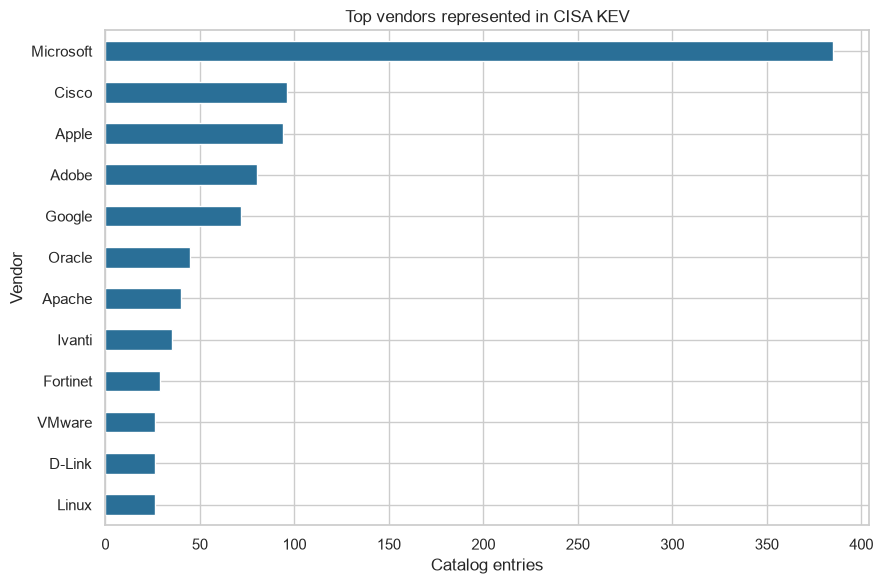

In [4]:
top_vendors = kev["vendorProject"].value_counts().head(12).sort_values()
ax = top_vendors.plot.barh(figsize=(9, 6), color="#2A6F97")
ax.set(title="Top vendors represented in CISA KEV", xlabel="Catalog entries", ylabel="Vendor")
plt.tight_layout(); plt.savefig(FIGURES / "top_vendors.png", dpi=160); plt.show()

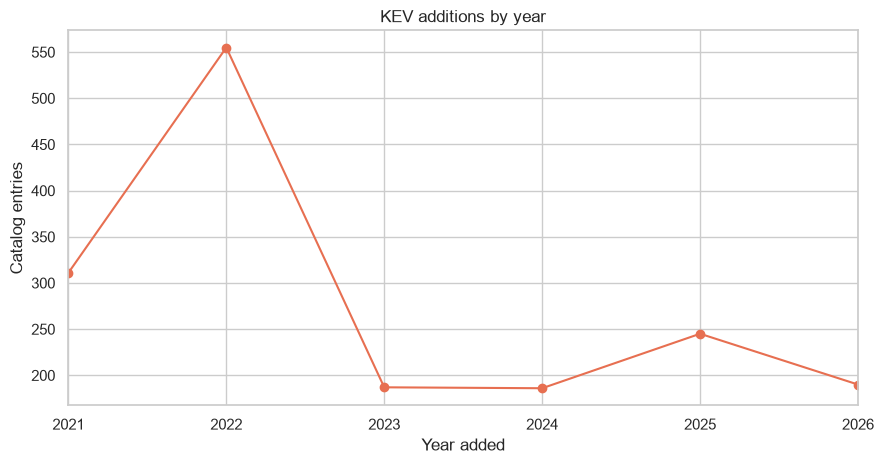

In [5]:
yearly = kev.set_index("dateAdded").resample("YS").size()
ax = yearly.plot(figsize=(9, 4.8), marker="o", color="#E76F51")
ax.set(title="KEV additions by year", xlabel="Year added", ylabel="Catalog entries")
plt.tight_layout(); plt.savefig(FIGURES / "yearly_additions.png", dpi=160); plt.show()

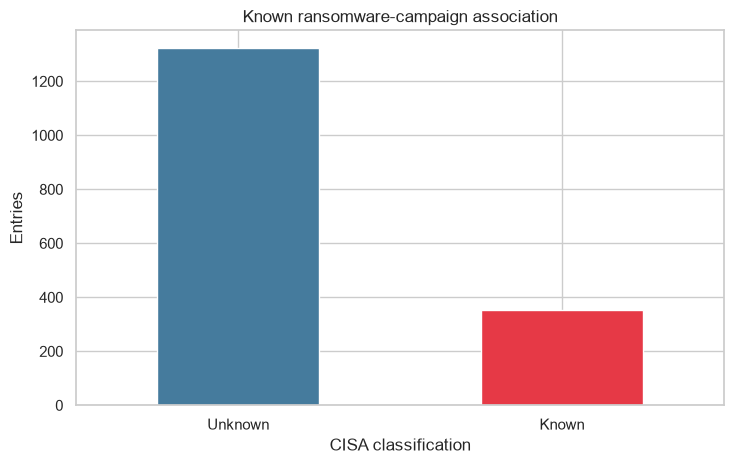

In [6]:
ransom = kev["knownRansomwareCampaignUse"].fillna("Unknown").value_counts()
ax = ransom.plot.bar(figsize=(7.5, 4.8), color=["#457B9D", "#E63946", "#A8DADC"])
ax.set(title="Known ransomware-campaign association", xlabel="CISA classification", ylabel="Entries")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIGURES / "ransomware_association.png", dpi=160); plt.show()

## Findings and reflection

The catalog is concentrated among a relatively small number of widely deployed
vendors, but it covers many organizations and products. Annual additions are not
a direct measure of attacker activity because catalog policy and reporting change
over time. The ransomware field is useful for prioritization, although “Unknown”
must not be interpreted as evidence that ransomware use is absent. The most
important workflow benefit was making every type conversion and quality check
visible. In Git, I would commit the raw snapshot separately, then the cleaning
functions, tests, figures, and report so each analytical decision can be reviewed
or reverted independently.